In [33]:
import pandas as pd 
import numpy as np 
from collections import deque
import os
import matplotlib.pyplot as plt

### Reactive Threshold: In this simulation cooking is started once the amount of food is less than the threshold, which in this case is 35 

In [34]:
def fixed_simulation(dataset):
    ## Using the same metrics 
    records = []
    waiting_times = [] ## Calculating the total time student had to wait 
    lunch_duration = 120 ## The lunch will run for 120 minutes 
    cooking_time = 10 ## Total time required to cook the food 
    batch_size = 65 ## Portions produced per batch 
    available_portions = 65 ## Food currently ready to serve 
    cooking_finish_time = None ## No batch is getting cooked currently 
    queue = deque() ## Starting unique queue for each of the input
    batches_started = 0
    reactive_threshold = 35 ## Threshold to check to start cooking again 
    for _, row in dataset.sort_values("minutes").iterrows():
        minute = int(row['minutes']) ## Minute count 
        arrivals = int(row['arriving_students']) ## Total number of students arriving in that minute 
        ### Adding the food 
        if cooking_finish_time is not None: ## If something is getting cooked
            if minute >= cooking_finish_time: ## If the minute or time
                available_portions += batch_size ## We add the total food to the batch size 
                cooking_finish_time = None 
        queue.extend([minute] * arrivals) ## Extend queue by each people arrivals per minute. if 3 people come in minute 10, the queue will be extended by [10,10,10]
        food_served = min(available_portions, len(queue)) ## The food will be served if there is available 
        for _ in range(food_served): ## Looping through the ones who got served
            arrival_minute = queue.popleft() ## Finding the minute they came in
            waiting_times.append(minute-arrival_minute) ## Minute now and the time they were served and appending the waiting time to the list
        available_portions -= food_served ## Decreasing the available_portions with the food served

        ### When to cook the batch 
        if (cooking_finish_time is None and available_portions < reactive_threshold and minute + cooking_time <= lunch_duration ):
            cooking_finish_time = minute + cooking_time ## If the minute is 30 and the food is need at minute 30 it will take 10 minutes to make the food meaning the fodd will be available at 30 + 10 = 40 
            batches_started += 1 ## Total number of batches cooked 


        records.append({
                        "minute": minute,
                        "arrivals": arrivals,
                        "fixed_cooking_minute": 15,
                        "available_portions": available_portions,
                        "students_waiting": len(queue),
                        "cooking": cooking_finish_time is not None
        })
    simulation_result = pd.DataFrame(records)
    return simulation_result, waiting_times

### Running model through each data

In [35]:
dataset_path = '../CafeteriaSimulation/simulation_datas/'
datasets = []

for filename in os.listdir(dataset_path):
    if filename.endswith('.csv'):
        filepath = os.path.join(dataset_path, filename) ### Creating a file path for each directory
        data = pd.read_csv(filepath)
        datasets.append(data)

### Checking the simulation against allt he data 

                total_arrivals
total_arrivals        1.000000
leftover             -0.306170
waiting_end           0.048307
mean_wait             0.827158
p95_wait              0.681893
max_queue             0.609836


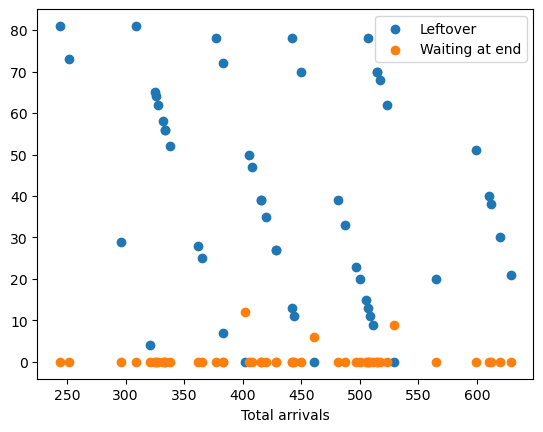

In [36]:
rows = []
for d in datasets:
    result, waits = fixed_simulation(d)
    rows.append({
        "total_arrivals": d["arriving_students"].sum(),
        "leftover": result["available_portions"].iloc[-1],
        "waiting_end": result["students_waiting"].iloc[-1],
        "mean_wait": np.mean(waits),
        "p95_wait": np.percentile(waits, 95),
        "max_queue": result["students_waiting"].max(),
    })

summary = pd.DataFrame(rows)
print(summary.corr()[["total_arrivals"]])

plt.scatter(summary["total_arrivals"], summary["leftover"], label="Leftover")
plt.scatter(summary["total_arrivals"], summary["waiting_end"], label="Waiting at end")
plt.xlabel("Total arrivals"); plt.legend(); plt.show()

In [37]:
summary.head(10)

,total_arrivals,leftover,waiting_end,mean_wait,p95_wait,max_queue
0,629,21,0,0.537361,3.0,31
1,529,0,9,0.334615,3.0,21
2,408,47,0,0.370098,3.0,25
3,505,15,0,0.461386,3.0,22
4,402,0,12,0.300000,2.0,24
5,296,29,0,0.087838,0.0,14
6,515,70,0,0.314563,2.0,18
7,610,40,0,0.449180,3.0,24
8,612,38,0,0.509804,3.0,26
9,338,52,0,0.236686,2.0,24
